In [101]:
import os
import zipfile

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision.models as models
from torchvision import datasets, transforms

from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [103]:
if torch.backends.mps.is_available():
    device = torch.device("mps")

elif torch.cuda.is_available():
    device = torch.device("cuda")

else:
    device = torch.device("cpu")

print("Device:", device)


Device: cpu


In [105]:
zip_path = "dataset.zip"
extract_path = "extracted_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [107]:
dataset_path = None

for root, dirs, files in os.walk(extract_path):

    if "cats" in dirs and "dogs" in dirs:
        dataset_path = root
        break

print("Dataset path:", dataset_path)

Dataset path: extracted_dataset/dataset


In [111]:
import shutil

training_data_path = os.path.join(extract_path, "training_data")

os.makedirs(os.path.join(training_data_path, "cats"), exist_ok=True)
os.makedirs(os.path.join(training_data_path, "dogs"), exist_ok=True)

# Copy cat training images
cats_images = os.path.join(dataset_path, "cats", "images")

for filename in os.listdir(cats_images):
    source = os.path.join(cats_images, filename)
    destination = os.path.join(training_data_path, "cats", filename)

    if os.path.isfile(source):
        shutil.copy2(source, destination)


# Copy dog training images
dogs_images = os.path.join(dataset_path, "dogs", "images")

for filename in os.listdir(dogs_images):
    source = os.path.join(dogs_images, filename)
    destination = os.path.join(training_data_path, "dogs", filename)

    if os.path.isfile(source):
        shutil.copy2(source, destination)

print("Training data prepared!")

Training data prepared!


In [115]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [117]:
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [119]:
full_train_dataset = datasets.ImageFolder(
    root=training_data_path,
    transform=train_transform
)

print("Classes:", full_train_dataset.classes)
print("Class mapping:", full_train_dataset.class_to_idx)
print("Total training images:", len(full_train_dataset))

Classes: ['cats', 'dogs']
Class mapping: {'cats': 0, 'dogs': 1}
Total training images: 200


In [123]:
train_size = int(0.7 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 140
Validation images: 60


In [125]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

print("Training and validation DataLoaders created!")

Training and validation DataLoaders created!


In [127]:
test_data_path = os.path.join(extract_path, "test_data")

os.makedirs(os.path.join(test_data_path, "cats"), exist_ok=True)
os.makedirs(os.path.join(test_data_path, "dogs"), exist_ok=True)

# Copy cat test images
cats_test = os.path.join(dataset_path, "cats", "test")

for filename in os.listdir(cats_test):

    source = os.path.join(cats_test, filename)
    destination = os.path.join(test_data_path, "cats", filename)

    if os.path.isfile(source):
        shutil.copy2(source, destination)


# Copy dog test images
dogs_test = os.path.join(dataset_path, "dogs", "test")

for filename in os.listdir(dogs_test):

    source = os.path.join(dogs_test, filename)
    destination = os.path.join(test_data_path, "dogs", filename)

    if os.path.isfile(source):
        shutil.copy2(source, destination)

print("Test data prepared!")

Test data prepared!


In [131]:
test_dataset = datasets.ImageFolder(
    root=test_data_path,
    transform=val_transform
)

print("Test classes:", test_dataset.classes)
print("Test class mapping:", test_dataset.class_to_idx)
print("Total test images:", len(test_dataset))

Test classes: ['cats', 'dogs']
Test class mapping: {'cats': 0, 'dogs': 1}
Total test images: 20


In [133]:
test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("Test DataLoader created!")

Test DataLoader created!


In [135]:
weights = models.MobileNet_V3_Large_Weights.DEFAULT

mobilenet_v3_large = models.mobilenet_v3_large(
    weights=weights
)

print("MobileNetV3-Large loaded!")

MobileNetV3-Large loaded!


In [137]:
mobilenet_v3_large.classifier[3] = nn.Linear(
    in_features=1280,
    out_features=2
)

In [139]:
mobilenet_v3_large = mobilenet_v3_large.to(device)

print("MobileNetV3 ready for cats vs dogs!")

MobileNetV3 ready for cats vs dogs!


In [141]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    mobilenet_v3_large.parameters(),
    lr=0.0001
)

In [143]:
num_epochs = 5

for epoch in range(num_epochs):

    mobilenet_v3_large.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = mobilenet_v3_large(inputs)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss
        running_loss += loss.item()

        # Calculate predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    train_accuracy = 100 * correct / total

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {average_loss:.4f} "
        f"Training Accuracy: {train_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.6128 Training Accuracy: 73.57%
Epoch [2/5] Loss: 0.3498 Training Accuracy: 92.14%
Epoch [3/5] Loss: 0.2110 Training Accuracy: 97.86%
Epoch [4/5] Loss: 0.1122 Training Accuracy: 98.57%
Epoch [5/5] Loss: 0.0658 Training Accuracy: 99.29%


In [145]:
mobilenet_v3_large.eval()

correct = 0
total = 0

all_val_labels = []
all_val_predictions = []

with torch.no_grad():

    for inputs, labels in val_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = mobilenet_v3_large(inputs)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

        all_val_labels.extend(
            labels.cpu().numpy()
        )

        all_val_predictions.extend(
            predicted.cpu().numpy()
        )

val_accuracy = 100 * correct / total

print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Accuracy: 90.00%


Validation Confusion Matrix:
[[21  6]
 [ 0 33]]


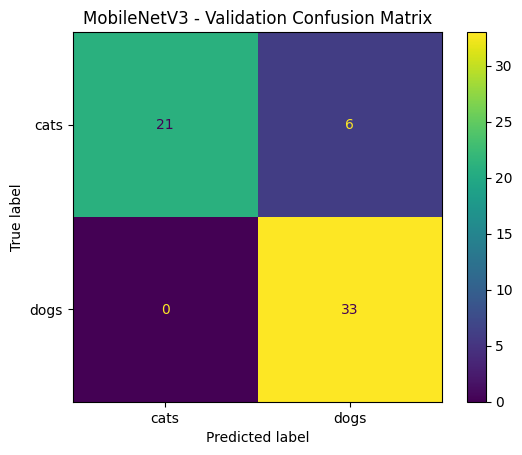

In [147]:
cm_val = confusion_matrix(
    all_val_labels,
    all_val_predictions
)

print("Validation Confusion Matrix:")
print(cm_val)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_val,
    display_labels=["cats", "dogs"]
)

disp.plot()

plt.title("MobileNetV3 - Validation Confusion Matrix")

plt.show()

In [149]:
mobilenet_v3_large.eval()

correct = 0
total = 0

all_test_labels = []
all_test_predictions = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = mobilenet_v3_large(inputs)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

        all_test_labels.extend(
            labels.cpu().numpy()
        )

        all_test_predictions.extend(
            predicted.cpu().numpy()
        )

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 95.00%


Test Confusion Matrix:
[[ 9  1]
 [ 0 10]]


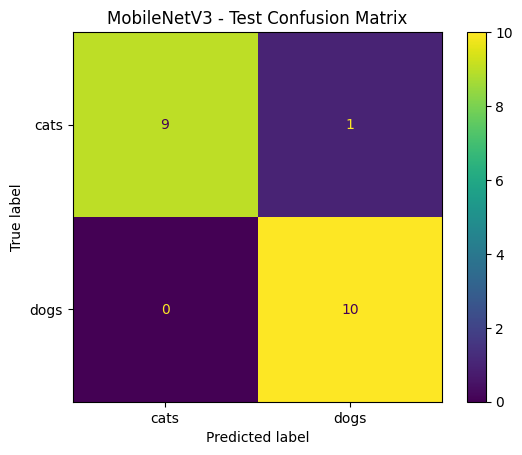

In [151]:
cm_test = confusion_matrix(
    all_test_labels,
    all_test_predictions
)

print("Test Confusion Matrix:")
print(cm_test)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["cats", "dogs"]
)

disp.plot()

plt.title("MobileNetV3 - Test Confusion Matrix")

plt.show()

In [153]:
torch.save(
    mobilenet_v3_large.state_dict(),
    "mobilenetv3_cats_dogs.pth"
)

print("Model saved successfully!")

Model saved successfully!
